# NIÑO-PREDICT — 02: Modelado Predictivo y Simulación Súper El Niño 2026/2027 (+2.7°C)

Este notebook implementa la **arquitectura acoplada de Machine Learning de dos etapas (*Two-Stage Hurdle Model*)**, la **validación temporal fuera de muestra en eventos extremos históricos (Súper El Niño 2015/16)** y la **simulación prospectiva con bandas de incertidumbre al 80% de confianza** para la campaña **2026/2027** bajo un escenario extremo de **$+2.7^\circ\text{C}$ ONI**.

### Arquitectura de Modelado:
1. **`model_yield` (LGBMRegressor):** Predice el rendimiento potencial intensivo en $\text{kg/ha}$ sobre la superficie cosechable.
2. **`model_loss` (LGBMRegressor):** Predice la tasa de pérdida extensiva $[0, 1]$ generada por anegamiento, tormentas severas y falta de piso.
3. **Modelos Cuantílicos ($p10, p90$):** Cuantifican el riesgo asimétrico (escenarios optimista y pesimista).
4. **Validación Temporal OOT (2015/16):** Matriz de dispersión 1:1 de calidad de publicación.
5. **Hotspots con Incertidumbre:** Gráfico Lollipop departamental con barras de rango $[p10 - p90]$.
6. **Acoplamiento Físico y Exportación GIS:** Calcula $\text{Producción} = \text{Sembrada} \times (1 - \text{Pérdida}) \times \text{Rinde}$ y exporta `df_2026_super_nino.csv`.

In [4]:
# 1. Importación de Librerías Científicas
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Directorio de figuras
fig_dir = Path('../reports/figures') if Path('../reports').exists() else Path('reports/figures')
fig_dir.mkdir(parents=True, exist_ok=True)

# Configuración de visualización
pd.set_option('display.max_columns', 30)
print('Entorno de modelado inicializado.')


Entorno de modelado inicializado.


In [5]:
# 2. Carga del Dataset Analítico Consolidado (generado por 01_eda_limpieza_datos.ipynb)
possible_dirs = [Path('../data/processed'), Path('data/processed')]
data_dir = next((d for d in possible_dirs if d.exists()), Path('data/processed'))

parquet_path = data_dir / 'dataset_consolidado_57campanas.parquet'
csv_path = data_dir / 'dataset_consolidado_57campanas.csv'

if parquet_path.exists():
    print(f'Cargando dataset columnar desde: {parquet_path.resolve()}')
    df_core = pd.read_parquet(parquet_path)
elif csv_path.exists():
    print(f'Cargando dataset desde: {csv_path.resolve()}')
    df_core = pd.read_csv(csv_path)
else:
    raise FileNotFoundError('No se encontró el dataset consolidado. Por favor ejecute 01_eda_limpieza_datos.ipynb primero.')

print(f'Dataset cargado: {df_core.shape[0]:,} registros x {df_core.shape[1]} columnas.')
print(f'Campañas: {df_core["campana"].min()} a {df_core["campana"].max()}')


Cargando dataset columnar desde: C:\Users\nico_\OneDrive\Desktop\PROYECTOS\NIÑO-PREDICT\data\processed\dataset_consolidado_57campanas.parquet
Dataset cargado: 54,588 registros x 22 columnas.
Campañas: 1969/70 a 2025/26


In [6]:
# 3. Preparación de Features y Tipado Categórico para LightGBM
train_data = df_core.dropna(subset=['rendimiento_media_3c_previas', 'oni_ventana_critica']).copy()

features = [
    'id_provincia', 'id_departamento', 'cultivo_grupo', 'anio_inicio',
    'rendimiento_media_3c_previas', 'oni_ventana_critica', 'oni_lag_3m', 'fase_enso'
]
cat_cols = ['id_provincia', 'id_departamento', 'cultivo_grupo', 'fase_enso']

for c in cat_cols:
    train_data[c] = train_data[c].astype('category')

print(f'Registros listos para entrenamiento: {len(train_data):,}')
print(f'Features utilizadas: {features}')


Registros listos para entrenamiento: 53,139
Features utilizadas: ['id_provincia', 'id_departamento', 'cultivo_grupo', 'anio_inicio', 'rendimiento_media_3c_previas', 'oni_ventana_critica', 'oni_lag_3m', 'fase_enso']


--- PRUEBA CIEGA FUERA DE MUESTRA EN EL SÚPER EL NIÑO 2015/16 ---


c:\Users\nico_\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\nico_\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\nico_\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\nico_\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1024, in __init__
    self._execute_child(args, executable, preexec_fn, c

• R2 Rendimiento:         0.861 (86.1% de varianza explicada)
• MAE Rendimiento:        580.1 kg/ha (RMSE: 824.8 kg/ha)
• MAE Tasa de Pérdida:    10.37% (RMSE: 15.26%)
• Producción Nacional:    Real = 113.20 MTn | Predicha = 117.15 MTn
• Error Nacional Agregado: +3.49%


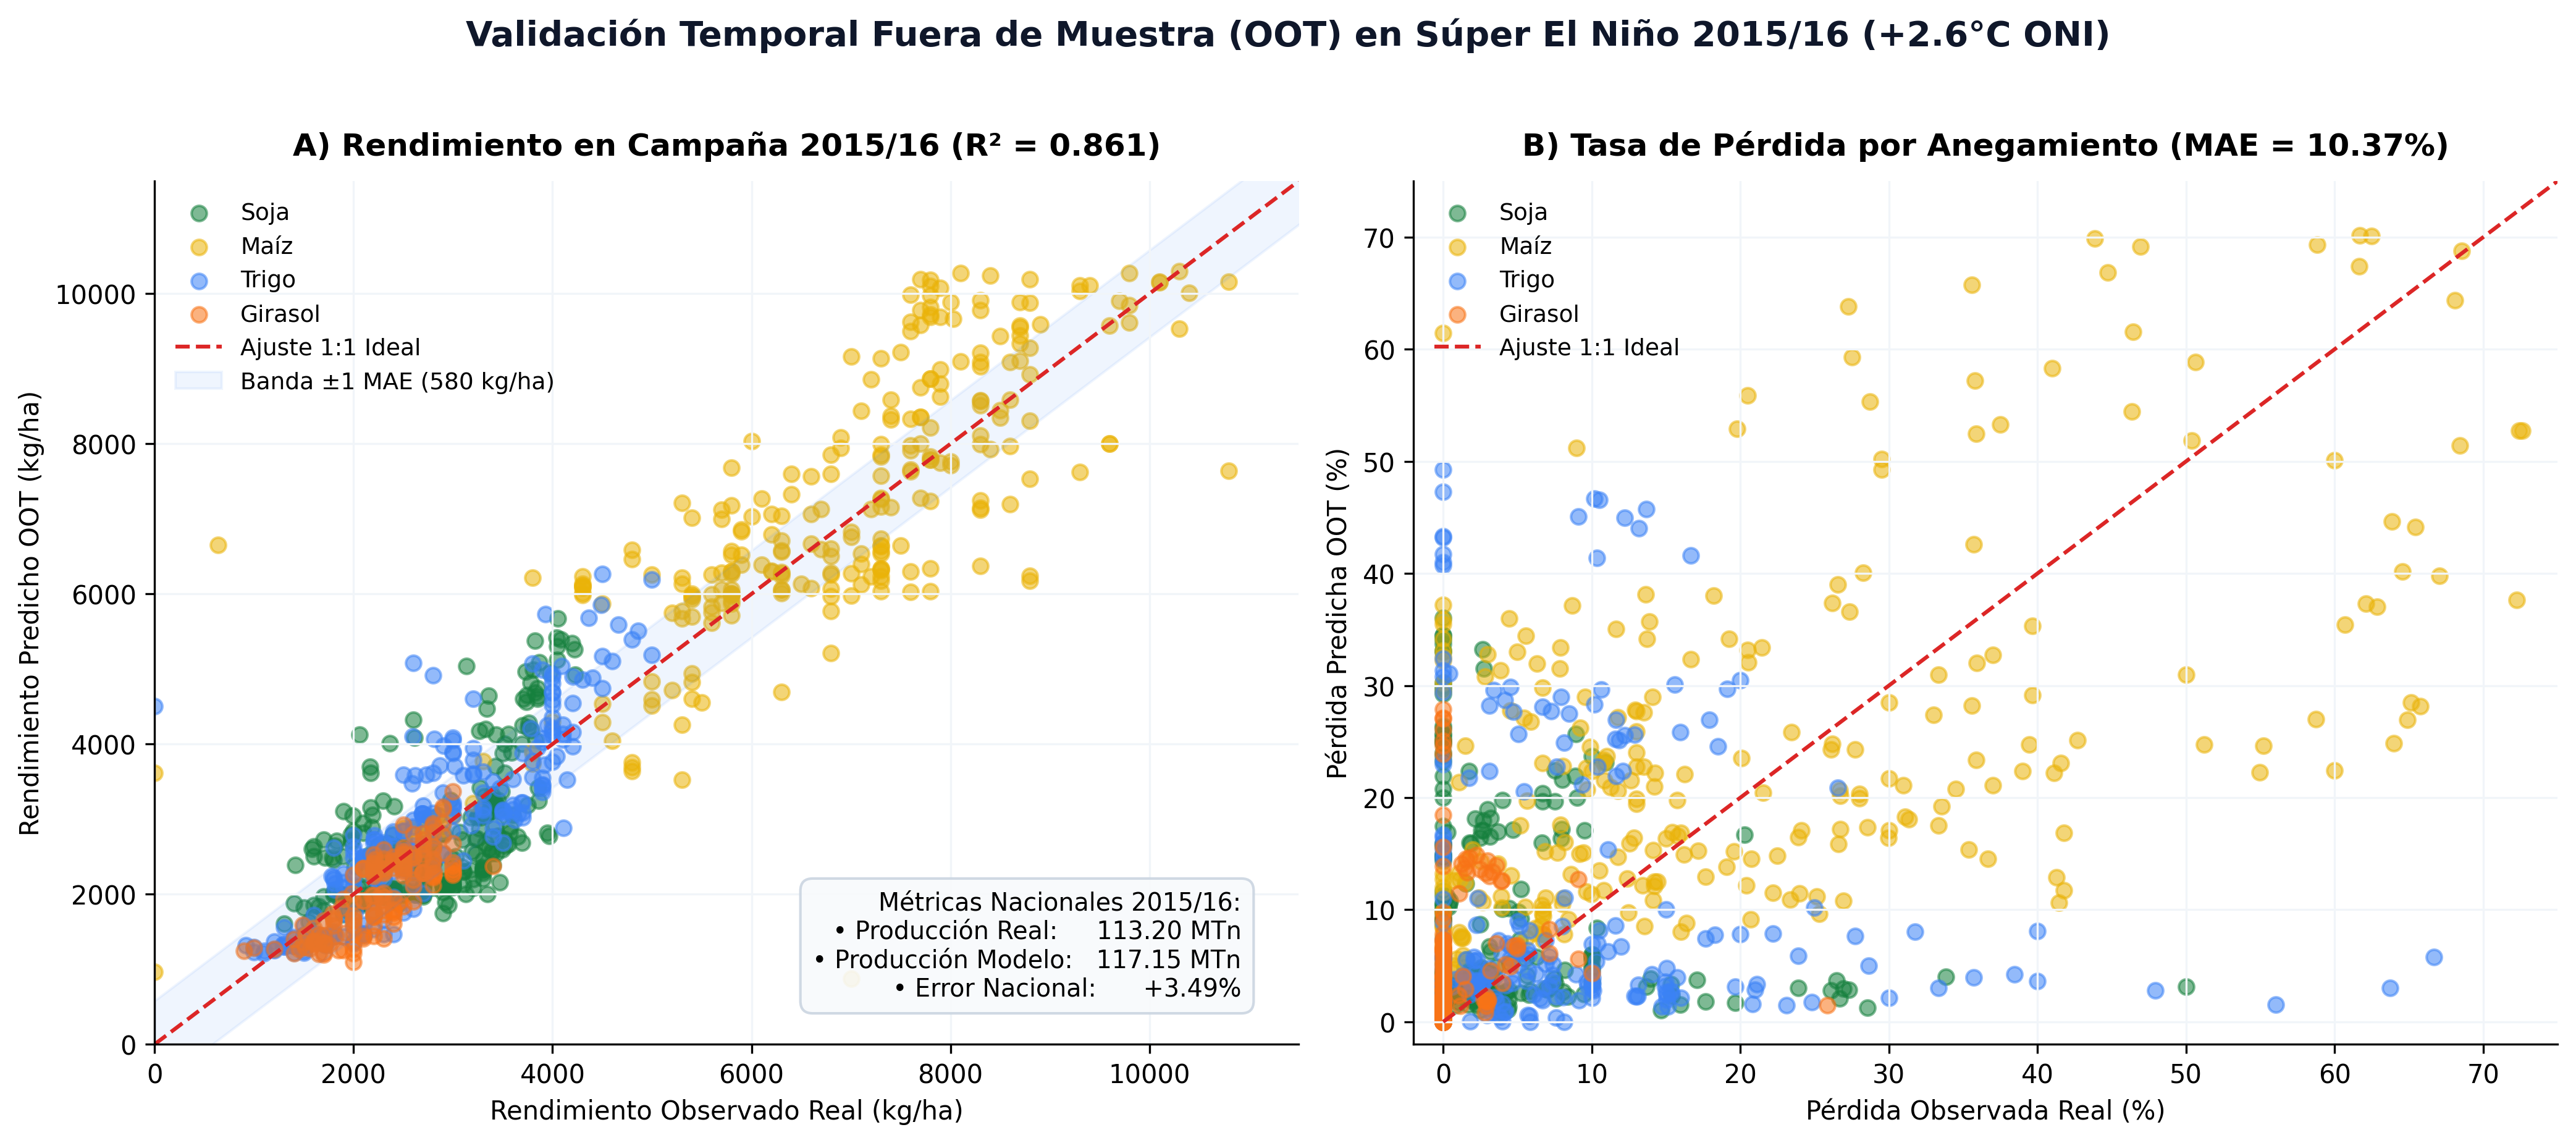

Figura 3 guardada en: C:\Users\nico_\OneDrive\Desktop\PROYECTOS\NIÑO-PREDICT\reports\figures\fig_03_validacion_oot_2015_16.png y C:\Users\nico_\OneDrive\Desktop\PROYECTOS\NIÑO-PREDICT\reports\figures\fig_03_validacion_oot_2015_16.svg


In [7]:
# =============================================================================
# 4. VALIDACIÓN TEMPORAL FUERA DE MUESTRA (OUT-OF-TIME): SÚPER EL NIÑO 2015/16
# =============================================================================
print('--- PRUEBA CIEGA FUERA DE MUESTRA EN EL SÚPER EL NIÑO 2015/16 ---')
train_oot = train_data[train_data['anio_inicio'] < 2015].copy()
test_oot = train_data[train_data['anio_inicio'] == 2015].copy()

# Ajuste de modelos OOT
m_y_oot = LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=31, random_state=42, verbose=-1)
m_y_oot.fit(train_oot[features], train_oot['rendimiento_kg_ha'])
pred_y_oot = np.maximum(0.0, m_y_oot.predict(test_oot[features]))

m_l_oot = LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=31, random_state=42, verbose=-1)
m_l_oot.fit(train_oot[features], train_oot['tasa_perdida'])
pred_l_oot = np.clip(m_l_oot.predict(test_oot[features]), 0.0, 1.0)

# Métricas
r2_y = r2_score(test_oot['rendimiento_kg_ha'], pred_y_oot)
mae_y = mean_absolute_error(test_oot['rendimiento_kg_ha'], pred_y_oot)
rmse_y = np.sqrt(mean_squared_error(test_oot['rendimiento_kg_ha'], pred_y_oot))
mae_l = mean_absolute_error(test_oot['tasa_perdida'], pred_l_oot)
rmse_l = np.sqrt(mean_squared_error(test_oot['tasa_perdida'], pred_l_oot))

# Producción Nacional Agregada OOT
prod_real_15 = test_oot['produccion_tn'].sum() / 1e6
prod_pred_15 = (test_oot['sup_sembrada_ha'] * (1.0 - pred_l_oot) * pred_y_oot).sum() / 1e9
err_prod_15 = ((prod_pred_15 - prod_real_15) / prod_real_15) * 100

print(f'• R2 Rendimiento:         {r2_y:.3f} ({r2_y*100:.1f}% de varianza explicada)')
print(f'• MAE Rendimiento:        {mae_y:.1f} kg/ha (RMSE: {rmse_y:.1f} kg/ha)')
print(f'• MAE Tasa de Pérdida:    {mae_l*100:.2f}% (RMSE: {rmse_l*100:.2f}%)')
print(f'• Producción Nacional:    Real = {prod_real_15:.2f} MTn | Predicha = {prod_pred_15:.2f} MTn')
print(f'• Error Nacional Agregado: {err_prod_15:+.2f}%')

# --- VISUALIZACIÓN DE PUBLICACIÓN: MATRIZ DE VALIDACIÓN OOT (FIGURA 3) ---
crop_pal = {'Soja': '#15803d', 'Maíz': '#eab308', 'Trigo': '#3b82f6', 'Girasol': '#f97316'}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), dpi=300)

# Panel A: Rendimiento
for crp, col in crop_pal.items():
    mask = test_oot['cultivo_grupo'] == crp
    ax1.scatter(test_oot.loc[mask, 'rendimiento_kg_ha'], pred_y_oot[mask], alpha=0.55, color=col, s=35, label=crp)
lims_y = [0, 12000]
ax1.plot(lims_y, lims_y, color='#dc2626', linestyle='--', linewidth=1.5, label='Ajuste 1:1 Ideal')
ax1.fill_between(lims_y, [x - mae_y for x in lims_y], [x + mae_y for x in lims_y], color='#3b82f6', alpha=0.08, label=f'Banda ±1 MAE ({mae_y:.0f} kg/ha)')
ax1.set_title(f'A) Rendimiento en Campaña 2015/16 (R² = {r2_y:.3f})', fontweight='bold', fontsize=12, pad=10)
ax1.set_xlabel('Rendimiento Observado Real (kg/ha)', fontweight='medium')
ax1.set_ylabel('Rendimiento Predicho OOT (kg/ha)', fontweight='medium')
ax1.set_xlim(0, 11500)
ax1.set_ylim(0, 11500)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(color='#f1f5f9', linestyle='-', linewidth=0.8)
ax1.legend(loc='upper left', frameon=False, fontsize=9)

# Panel B: Pérdida
for crp, col in crop_pal.items():
    mask = test_oot['cultivo_grupo'] == crp
    ax2.scatter(test_oot.loc[mask, 'tasa_perdida'] * 100, pred_l_oot[mask] * 100, alpha=0.55, color=col, s=35, label=crp)
ax2.plot([0, 80], [0, 80], color='#dc2626', linestyle='--', linewidth=1.5, label='Ajuste 1:1 Ideal')
ax2.set_title(f'B) Tasa de Pérdida por Anegamiento (MAE = {mae_l*100:.2f}%)', fontweight='bold', fontsize=12, pad=10)
ax2.set_xlabel('Pérdida Observada Real (%)', fontweight='medium')
ax2.set_ylabel('Pérdida Predicha OOT (%)', fontweight='medium')
ax2.set_xlim(-2, 75)
ax2.set_ylim(-2, 75)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(color='#f1f5f9', linestyle='-', linewidth=0.8)
ax2.legend(loc='upper left', frameon=False, fontsize=9)

summary_text = f'Métricas Nacionales 2015/16:\n• Producción Real:     {prod_real_15:.2f} MTn\n• Producción Modelo:   {prod_pred_15:.2f} MTn\n• Error Nacional:      {err_prod_15:+.2f}%'
ax1.text(0.95, 0.05, summary_text, transform=ax1.transAxes, fontsize=9.5, verticalalignment='bottom', horizontalalignment='right', bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8fafc', edgecolor='#cbd5e1', alpha=0.9))

plt.suptitle('Validación Temporal Fuera de Muestra (OOT) en Súper El Niño 2015/16 (+2.6°C ONI)', fontsize=13.5, fontweight='bold', y=1.02, color='#0f172a')
plt.tight_layout()

p3_png = fig_dir / 'fig_03_validacion_oot_2015_16.png'
p3_svg = fig_dir / 'fig_03_validacion_oot_2015_16.svg'
fig.savefig(p3_png, dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig(p3_svg, format='svg', bbox_inches='tight')
plt.show()
print(f'Figura 3 guardada en: {p3_png.resolve()} y {p3_svg.resolve()}')


In [8]:
# =============================================================================
# 5. ENTRENAMIENTO DE LA ARQUITECTURA HURDLE CON BANDAS DE INCERTIDUMBRE (p10, p50, p90)
# =============================================================================
print('Entrenando arquitectura acoplada sobre las 57 campañas completas...')

# Modelos de Rendimiento
model_yield = LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=31, random_state=42, verbose=-1)
model_yield.fit(train_data[features], train_data['rendimiento_kg_ha'])

model_yield_p10 = LGBMRegressor(objective='quantile', alpha=0.10, n_estimators=300, learning_rate=0.03, num_leaves=31, random_state=42, verbose=-1)
model_yield_p10.fit(train_data[features], train_data['rendimiento_kg_ha'])

model_yield_p90 = LGBMRegressor(objective='quantile', alpha=0.90, n_estimators=300, learning_rate=0.03, num_leaves=31, random_state=42, verbose=-1)
model_yield_p90.fit(train_data[features], train_data['rendimiento_kg_ha'])

# Modelos de Tasa de Pérdida
model_loss = LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=31, random_state=42, verbose=-1)
model_loss.fit(train_data[features], train_data['tasa_perdida'])

model_loss_p10 = LGBMRegressor(objective='quantile', alpha=0.10, n_estimators=300, learning_rate=0.03, num_leaves=31, random_state=42, verbose=-1)
model_loss_p10.fit(train_data[features], train_data['tasa_perdida'])

model_loss_p90 = LGBMRegressor(objective='quantile', alpha=0.90, n_estimators=300, learning_rate=0.03, num_leaves=31, random_state=42, verbose=-1)
model_loss_p90.fit(train_data[features], train_data['tasa_perdida'])

print('Modelos puntuales y cuantílicos entrenados con éxito.')


Entrenando arquitectura acoplada sobre las 57 campañas completas...
Modelos puntuales y cuantílicos entrenados con éxito.


In [9]:
# =============================================================================
# 6. SIMULACIÓN PROSPECTIVA SÚPER EL NIÑO 2026/2027 (+2.7°C ONI)
# =============================================================================
recent_years = [2021, 2022, 2023]
df_recent = df_core[df_core['anio_inicio'].isin(recent_years)].copy()

df_2026 = (
    df_recent.groupby(['id_provincia', 'provincia', 'id_departamento', 'departamento', 'cultivo_grupo'], as_index=False, observed=True)
    .agg(
        sup_sembrada_ha=('sup_sembrada_ha', 'mean'),
        rendimiento_media_3c_previas=('rendimiento_kg_ha', 'mean')
    )
)

df_2026['anio_inicio'] = 2026
df_2026['oni_ventana_critica'] = 2.7
df_2026['oni_lag_3m'] = 2.4
df_2026['fase_enso'] = 'El Niño'

for c in cat_cols:
    df_2026[c] = df_2026[c].astype('category')

# Inferencia de Rendimientos (kg/ha)
df_2026['pred_rendimiento_kg_ha'] = np.maximum(0.0, model_yield.predict(df_2026[features]))
df_2026['pred_rendimiento_p10_kg_ha'] = np.maximum(0.0, model_yield_p10.predict(df_2026[features]))
df_2026['pred_rendimiento_p90_kg_ha'] = np.maximum(0.0, model_yield_p90.predict(df_2026[features]))

# Inferencia de Tasa de Pérdida
df_2026['pred_tasa_perdida'] = np.clip(model_loss.predict(df_2026[features]), 0.0, 1.0)
df_2026['pred_tasa_perdida_p10'] = np.clip(model_loss_p10.predict(df_2026[features]), 0.0, 1.0)
df_2026['pred_tasa_perdida_p90'] = np.clip(model_loss_p90.predict(df_2026[features]), 0.0, 1.0)

# Acoplamiento Físico Agronómico
df_2026['pred_sup_cosechada_ha'] = df_2026['sup_sembrada_ha'] * (1.0 - df_2026['pred_tasa_perdida'])
df_2026['pred_sup_perdida_ha'] = df_2026['sup_sembrada_ha'] * df_2026['pred_tasa_perdida']

df_2026['pred_sup_perdida_p10_ha'] = df_2026['sup_sembrada_ha'] * df_2026['pred_tasa_perdida_p10']
df_2026['pred_sup_perdida_p90_ha'] = df_2026['sup_sembrada_ha'] * df_2026['pred_tasa_perdida_p90']

df_2026['pred_produccion_tn'] = (df_2026['pred_sup_cosechada_ha'] * df_2026['pred_rendimiento_kg_ha']) / 1000.0
df_2026['pred_produccion_p10_tn'] = (df_2026['sup_sembrada_ha'] * (1.0 - df_2026['pred_tasa_perdida_p90']) * df_2026['pred_rendimiento_p10_kg_ha']) / 1000.0
df_2026['pred_produccion_p90_tn'] = (df_2026['sup_sembrada_ha'] * (1.0 - df_2026['pred_tasa_perdida_p10']) * df_2026['pred_rendimiento_p90_kg_ha']) / 1000.0

df_2026['cde'] = df_2026.apply(lambda r: f"{int(r['id_provincia']):02d}{int(r['id_departamento']):03d}", axis=1)
print(f'Simulación 2026/27 completada para {len(df_2026):,} combinaciones departamento-cultivo.')


Simulación 2026/27 completada para 1,080 combinaciones departamento-cultivo.


=== BALANCE NACIONAL PROYECTADO CAMPAÑA 2026/2027 (SÚPER EL NIÑO +2.7°C) ===
cultivo_grupo  Sembrada_Mha  Perdida_Central_Mha  Perdida_p10_Mha  Perdida_p90_Mha  Pct_Perdida_Central  Produccion_Central_MTn  Rinde_Ponderado_Kg_Ha
      Girasol          2.11                 0.04             0.00             0.07                 1.69                    5.20               2,506.32
         Maíz         10.78                 2.32             0.10             4.40                21.53                   56.87               6,724.29
         Soja         16.24                 0.58             0.00             1.53                 3.56                   46.72               2,982.79
        Trigo          6.30                 0.27             0.00             0.72                 4.32                   20.90               3,465.75

=== TOP 12 DEPARTAMENTOS CON MAYOR PÉRDIDA DE ÁREA (RIESGO INUNDACIÓN / FALTA DE PISO) ===
cultivo_grupo           provincia      departamento  sup_sembrada_ha  pred_s

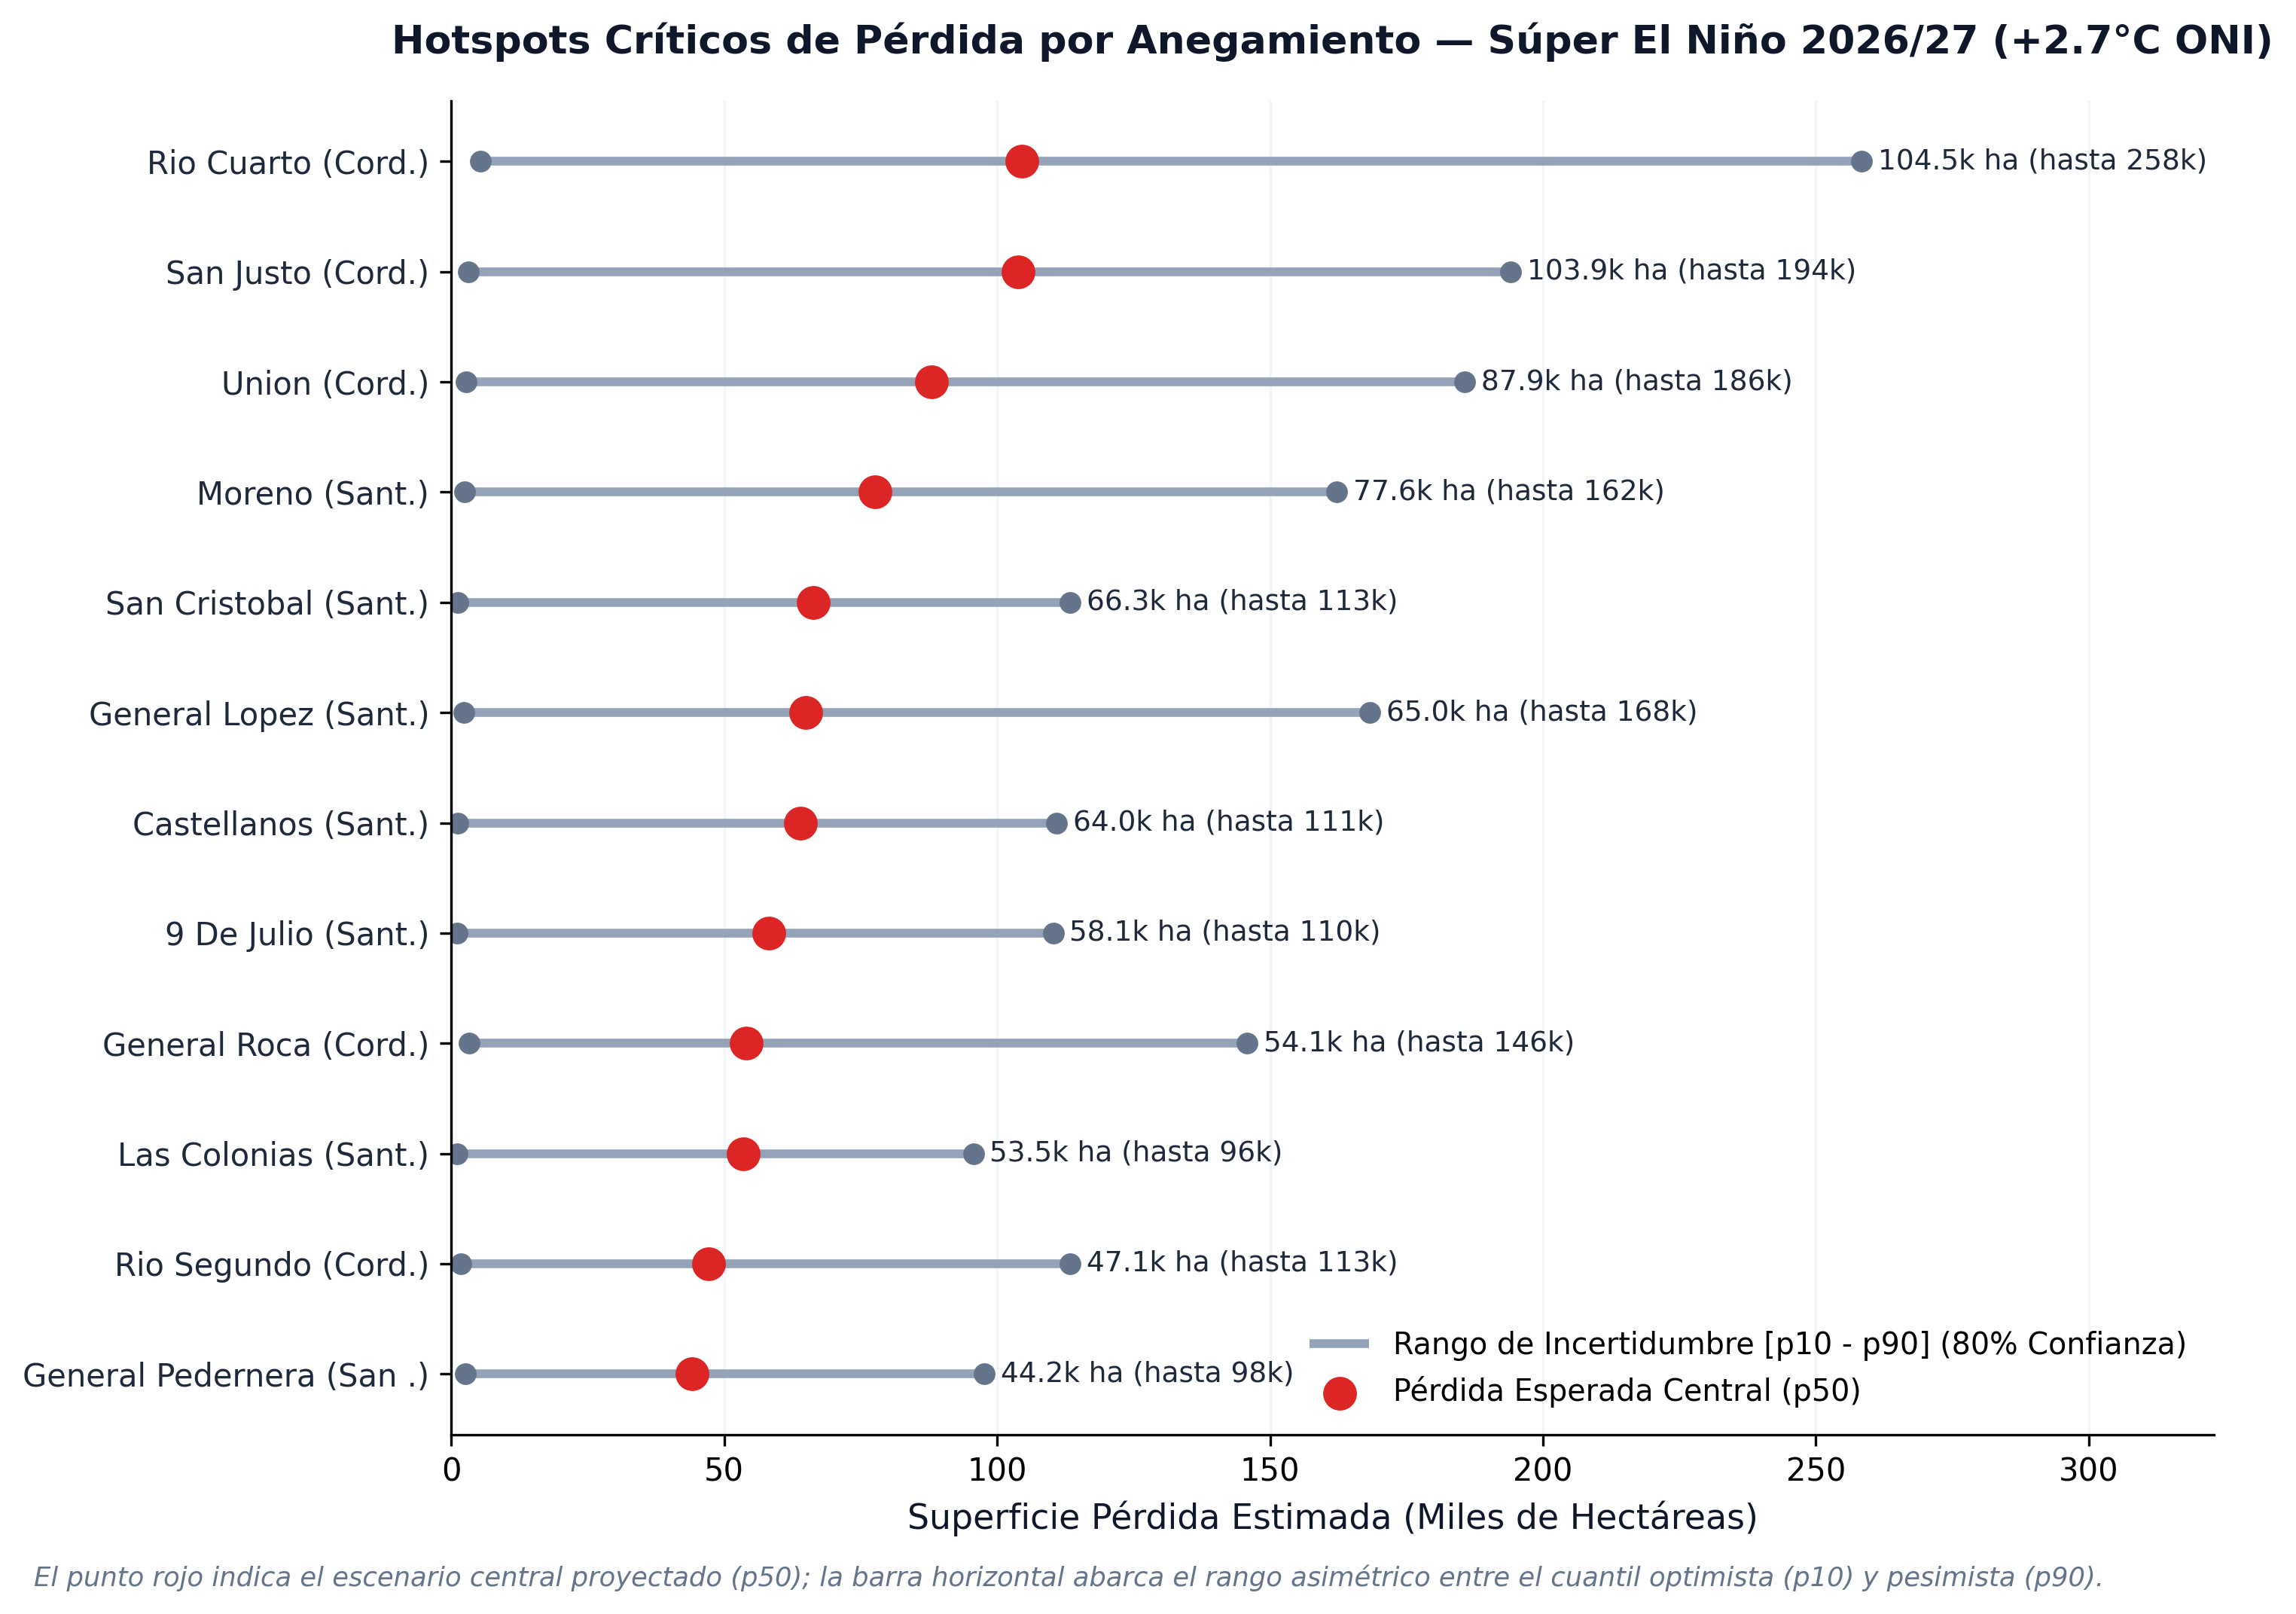

Figura 4 guardada en: C:\Users\nico_\OneDrive\Desktop\PROYECTOS\NIÑO-PREDICT\reports\figures\fig_04_hotspots_anegamiento_2026.png y C:\Users\nico_\OneDrive\Desktop\PROYECTOS\NIÑO-PREDICT\reports\figures\fig_04_hotspots_anegamiento_2026.svg


In [10]:
# =============================================================================
# 7. BALANCE NACIONAL PROYECTADO E INTERVALOS DE CONFIANZA AL 80%
# =============================================================================
tabla_nacional = (
    df_2026.groupby('cultivo_grupo', as_index=False, observed=True)
    .agg(
        Sembrada_Mha=('sup_sembrada_ha', lambda x: x.sum() / 1e6),
        Cosechada_Mha=('pred_sup_cosechada_ha', lambda x: x.sum() / 1e6),
        Perdida_Central_Mha=('pred_sup_perdida_ha', lambda x: x.sum() / 1e6),
        Perdida_p10_Mha=('pred_sup_perdida_p10_ha', lambda x: x.sum() / 1e6),
        Perdida_p90_Mha=('pred_sup_perdida_p90_ha', lambda x: x.sum() / 1e6),
        Produccion_Central_MTn=('pred_produccion_tn', lambda x: x.sum() / 1e6),
        Produccion_p10_MTn=('pred_produccion_p10_tn', lambda x: x.sum() / 1e6),
        Produccion_p90_MTn=('pred_produccion_p90_tn', lambda x: x.sum() / 1e6)
    )
)
tabla_nacional['Rinde_Ponderado_Kg_Ha'] = (tabla_nacional['Produccion_Central_MTn'] * 1e9) / (tabla_nacional['Cosechada_Mha'] * 1e6)
tabla_nacional['Pct_Perdida_Central'] = (tabla_nacional['Perdida_Central_Mha'] / tabla_nacional['Sembrada_Mha']) * 100

print('=== BALANCE NACIONAL PROYECTADO CAMPAÑA 2026/2027 (SÚPER EL NIÑO +2.7°C) ===')
with pd.option_context('display.float_format', lambda v: f'{v:,.2f}'):
    print(tabla_nacional[['cultivo_grupo', 'Sembrada_Mha', 'Perdida_Central_Mha', 'Perdida_p10_Mha', 'Perdida_p90_Mha', 'Pct_Perdida_Central', 'Produccion_Central_MTn', 'Rinde_Ponderado_Kg_Ha']].to_string(index=False))

# Top 12 Departamentos con Mayor Superficie en Riesgo
top_riesgo = (
    df_2026.sort_values('pred_sup_perdida_ha', ascending=False)
    [['cultivo_grupo', 'provincia', 'departamento', 'sup_sembrada_ha', 'pred_sup_perdida_ha', 'pred_sup_perdida_p90_ha', 'pred_tasa_perdida', 'pred_rendimiento_kg_ha']]
    .head(12)
)

print('\n=== TOP 12 DEPARTAMENTOS CON MAYOR PÉRDIDA DE ÁREA (RIESGO INUNDACIÓN / FALTA DE PISO) ===')
with pd.option_context('display.float_format', lambda v: f'{v:,.2f}'):
    print(top_riesgo.to_string(index=False))

# --- VISUALIZACIÓN DE PUBLICACIÓN: LOLLIPOP DE HOTSPOTS CON INCERTIDUMBRE (FIGURA 4) ---
top12_agg = df_2026.groupby(['provincia', 'departamento'], as_index=False).agg(
    p50=('pred_sup_perdida_ha', 'sum'),
    p10=('pred_sup_perdida_p10_ha', 'sum'),
    p90=('pred_sup_perdida_p90_ha', 'sum')
).sort_values('p50', ascending=True).tail(12)

fig, ax = plt.subplots(figsize=(10, 7), dpi=300)
y_pos = np.arange(len(top12_agg))
labels = [f"{d.title()} ({p[:4].title()}.)" for d, p in zip(top12_agg['departamento'], top12_agg['provincia'])]

ax.hlines(y=y_pos, xmin=top12_agg['p10'] / 1e3, xmax=top12_agg['p90'] / 1e3, color='#94a3b8', linewidth=2.8, label='Rango de Incertidumbre [p10 - p90] (80% Confianza)')
ax.scatter(top12_agg['p10'] / 1e3, y_pos, color='#64748b', s=35, zorder=2)
ax.scatter(top12_agg['p90'] / 1e3, y_pos, color='#64748b', s=35, zorder=2)
ax.scatter(top12_agg['p50'] / 1e3, y_pos, color='#dc2626', s=95, zorder=3, label='Pérdida Esperada Central (p50)')

for i, (p50_v, p90_v) in enumerate(zip(top12_agg['p50'], top12_agg['p90'])):
    ax.text(p90_v / 1e3 + 3.0, i, f"{p50_v/1e3:.1f}k ha (hasta {p90_v/1e3:.0f}k)", va='center', fontsize=9, color='#1e293b', fontweight='medium')

ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=10, fontweight='medium', color='#1e293b')
ax.set_xlabel('Superficie Pérdida Estimada (Miles de Hectáreas)', fontweight='medium', fontsize=11, color='#0f172a')
ax.set_xlim(0, max(top12_agg['p90'] / 1e3) * 1.25)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='x', color='#f1f5f9', linestyle='-', linewidth=0.8)
ax.legend(loc='lower right', frameon=False, fontsize=9.5)

plt.title('Hotspots Críticos de Pérdida por Anegamiento — Súper El Niño 2026/27 (+2.7°C ONI)', fontweight='bold', fontsize=12.5, pad=15, color='#0f172a')
fig.text(0.02, -0.01, 'El punto rojo indica el escenario central proyectado (p50); la barra horizontal abarca el rango asimétrico entre el cuantil optimista (p10) y pesimista (p90).', fontsize=8.5, color='#64748b', style='italic')
plt.tight_layout()

p4_png = fig_dir / 'fig_04_hotspots_anegamiento_2026.png'
p4_svg = fig_dir / 'fig_04_hotspots_anegamiento_2026.svg'
fig.savefig(p4_png, dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig(p4_svg, format='svg', bbox_inches='tight')
plt.show()
print(f'Figura 4 guardada en: {p4_png.resolve()} y {p4_svg.resolve()}')


In [11]:
# =============================================================================
# 8. EXPORTACIÓN PARA EL MAPA INTERACTIVO Y DASHBOARDS (WFS INDEC)
# =============================================================================
out_csv = data_dir / 'df_2026_super_nino.csv'
df_2026.to_csv(out_csv, index=False)
print(f'Dataset de simulación 2026/27 guardado en: {out_csv.resolve()}')
print('Este archivo alimenta directamente el mapa interactivo departamental (mapa_inundaciones_2026.html).')


Dataset de simulación 2026/27 guardado en: C:\Users\nico_\OneDrive\Desktop\PROYECTOS\NIÑO-PREDICT\data\processed\df_2026_super_nino.csv
Este archivo alimenta directamente el mapa interactivo departamental (mapa_inundaciones_2026.html).
